# monitor_geometry: geometry run (`drc_geo_runs`), H, clusters and video

This notebook only **reads** results: it never starts a simulation. Runs are started with `python custom_runs.py` in the Anaconda Prompt. Keep the notebook in the project folder (next to `custom_runs.py` and the folder `custom_packages`).

Sections 1-2 read the geometry run. Sections 3-6 work on one saved sample of the main run (`drc_runs/L…_snapshot….npz`). Section 7 makes a video: it draws its own samples in this notebook (seconds to a few minutes) and saves only the `.mp4`.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from custom_packages import drc_sim as d
from custom_packages import drc_geometry as dg
from custom_packages import drc_height as dh
from custom_packages import drc_clusters as dc
from custom_packages import presentation_figures as pf      # figures for the slides -> Graficos/

print("geometry results:", dg.OUT_DIR)
print("snapshots:       ", d.OUT_DIR)

geometry results: C:\Users\bronk\Desktop\wwea 2.0\Ingenieria semestre 14\Simulacion Estocastico\Lab\Proyecto\6)simulation v4\drc_geo_runs
snapshots:        C:\Users\bronk\Desktop\wwea 2.0\Ingenieria semestre 14\Simulacion Estocastico\Lab\Proyecto\6)simulation v4\drc_runs


## 1. Progress and results of the geometry run

In [2]:
dg.status()

reading C:\Users\bronk\Desktop\wwea 2.0\Ingenieria semestre 14\Simulacion Estocastico\Lab\Proyecto\6)simulation v4\drc_geo_runs  (60 checkpoint files)
L=   64: 12 chains,  384000/384000 samples (100.0%), 38400 geometry samples, 0.32 core-hours
L=  128: 12 chains,  384000/384000 samples (100.0%), 38400 geometry samples, 0.81 core-hours
L=  256: 12 chains,  192000/192000 samples (100.0%), 19200 geometry samples, 1.54 core-hours
L=  512: 12 chains,   96000/96000 samples (100.0%), 9600 geometry samples, 3.83 core-hours
L= 1024: 12 chains,   48000/48000 samples (100.0%), 4800 geometry samples, 9.45 core-hours


In [3]:
res = dg.summarize()

Non-Gaussianity of h (GFF: variance ratio 1, excess kurtosis 0)
  L=   64 (384000 samples) modes  (1,1): var 0.964+-0.004 kurt +0.135+-0.011  (2,2): var 0.949+-0.002 kurt +0.042+-0.008  (3,3): var 0.946+-0.002 kurt +0.042+-0.005
               block-average kurtosis  L/32: +0.653+-0.003  L/16: +0.568+-0.003  L/8: +0.454+-0.004
  L=  128 (384000 samples) modes  (1,1): var 0.987+-0.006 kurt +0.055+-0.014  (2,2): var 0.974+-0.002 kurt +0.015+-0.008  (3,3): var 0.970+-0.002 kurt +0.003+-0.010
               block-average kurtosis  L/32: +0.338+-0.003  L/16: +0.283+-0.004  L/8: +0.223+-0.004
  L=  256 (192000 samples) modes  (1,1): var 1.004+-0.009 kurt +0.031+-0.013  (2,2): var 0.986+-0.005 kurt +0.010+-0.017  (3,3): var 0.979+-0.003 kurt +0.023+-0.009
               block-average kurtosis  L/32: +0.168+-0.004  L/16: +0.138+-0.005  L/8: +0.106+-0.005
  L=  512 (96000 samples) modes  (1,1): var 1.018+-0.008 kurt +0.020+-0.023  (2,2): var 0.999+-0.004 kurt +0.020+-0.019  (3,3): var 0.992+-0.

## 2. Box-counting dimensions and non-Gaussianity
Local slopes of log N(box) between consecutive box sizes, for the largest outermost cluster (expected 7/4) and for its outer boundary (expected 3/2). Look at the plateau at intermediate box sizes.

Second figure: sine modes of h (GFF: variance ratio 1, excess kurtosis 0) and block averages.

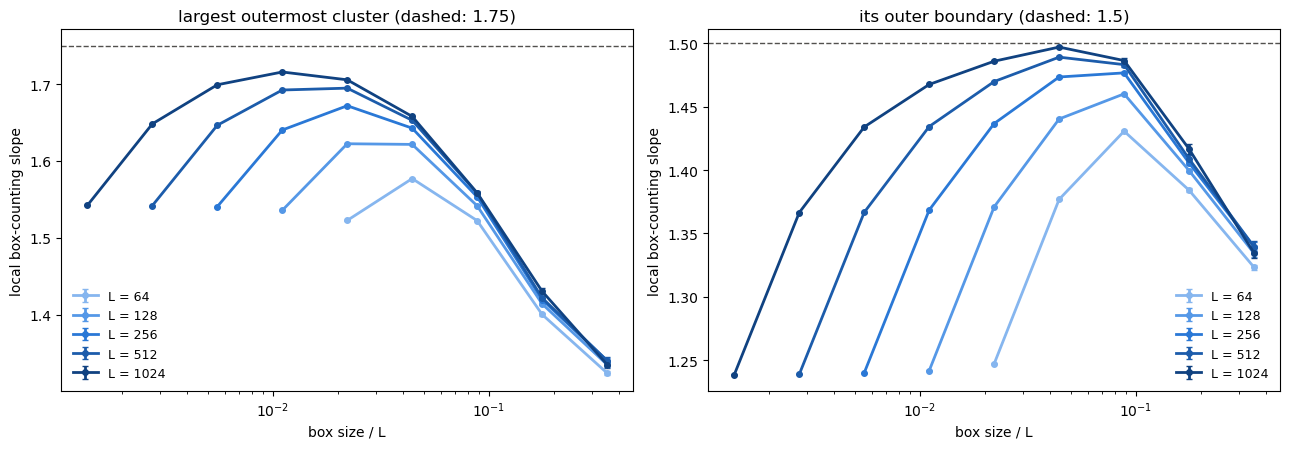

In [4]:
if res:
    dg.plot_dimensions(res); plt.show()

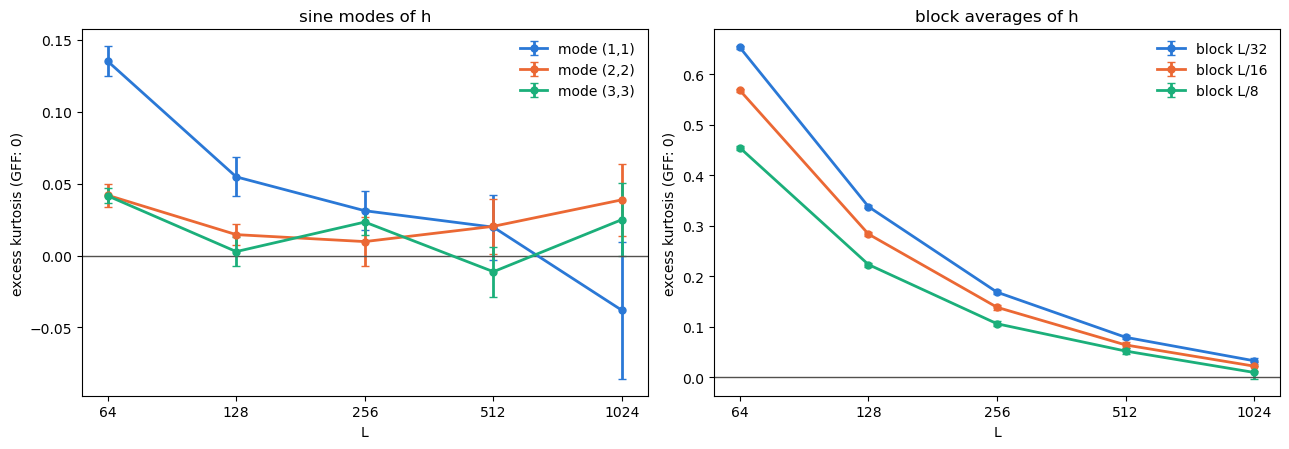

In [5]:
if res:
    dg.plot_kurtosis(res); plt.show()

## 3. Choose a saved sample
Everything below uses this sample.

In [6]:
L_show = 1024     # size
k_show = 0        # snapshot number: 0, 1 or 2
path = os.path.join(d.OUT_DIR, f"L{L_show}_snapshot{k_show}.npz")
L, omega1, omega2, h, n_odd = d.load_snapshot(path)
print("loaded", path)

loaded C:\Users\bronk\Desktop\wwea 2.0\Ingenieria semestre 14\Simulacion Estocastico\Lab\Proyecto\6)simulation v4\drc_runs\L1024_snapshot0.npz


## 4. Height function H of Theorem 2.1 on faces and vertices
H(u) − H(v) = ½ τ†(u) τ(v) for a face u and a vertex v of that face. H on the faces is h; H on the vertices is half-integer valued. `height_H` checks the relation on every vertex and stops with an error if it fails.

`window = (top row, left column, size)` is the piece shown in the third panel (faces = squares, vertices = discs).

H on faces:    (1023, 1023) values [-2. -1.  0.  1.  2.]
H on vertices: (1024, 1024) values [-2.5 -1.5 -0.5  0.5  1.5  2.5]


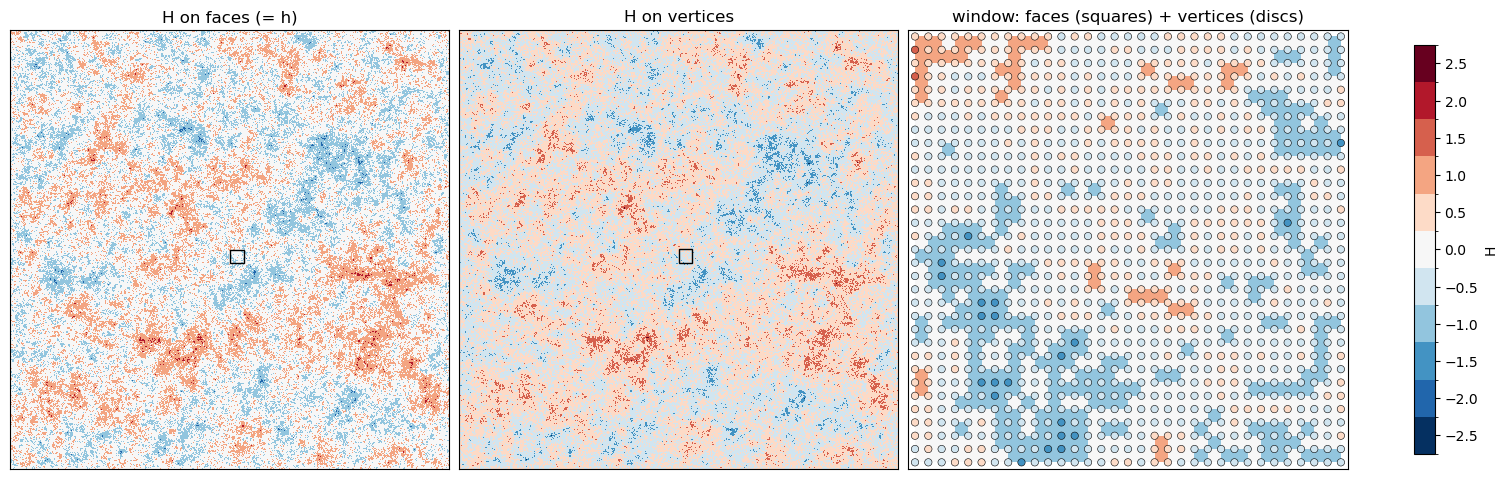

In [7]:
H = dh.height_H(L, omega1, omega2, h, rng=np.random.default_rng(0))
print("H on faces:   ", H["H_faces"].shape, "values", np.unique(H["H_faces"]))
print("H on vertices:", H["H_vertices"].shape, "values", np.unique(H["H_vertices"]))
dh.plot_H(H, window=(L // 2, L // 2, 32))      # add path=pf.ruta("H.png") to save it in Graficos/ instead of showing it
plt.show()

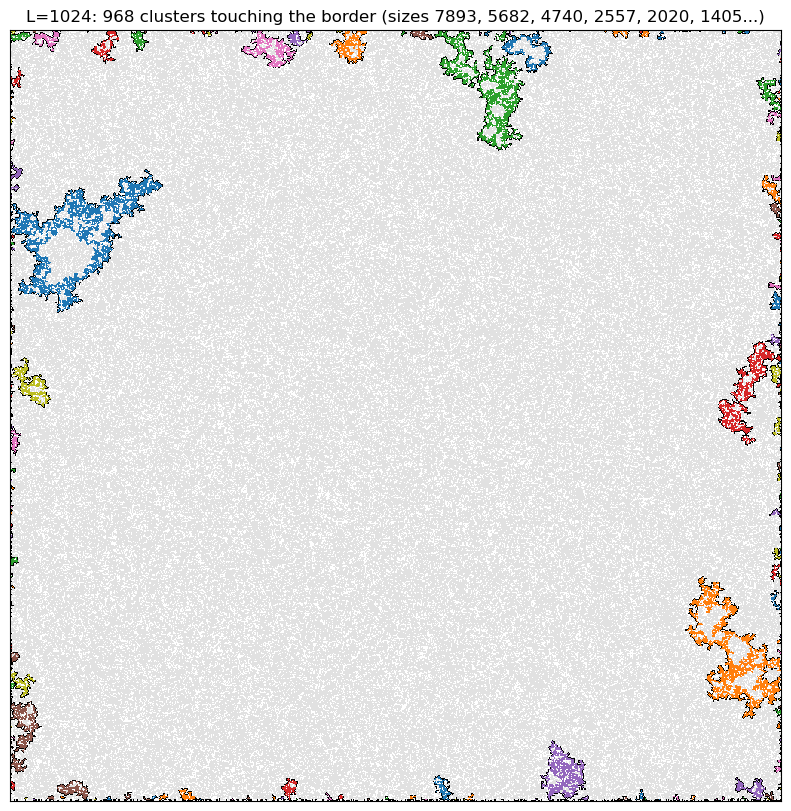

largest border clusters (label, vertices): [(62272, 7893), (238464, 5682), (403, 4740), (136219, 2557), (308349, 2020)]


In [8]:
fig, info = dc.draw_clusters(L, omega1, omega2, mode="border")      # add path=pf.ruta("clusters.png") to save it in Graficos/ instead
plt.show()
print("largest border clusters (label, vertices):", info[:5])

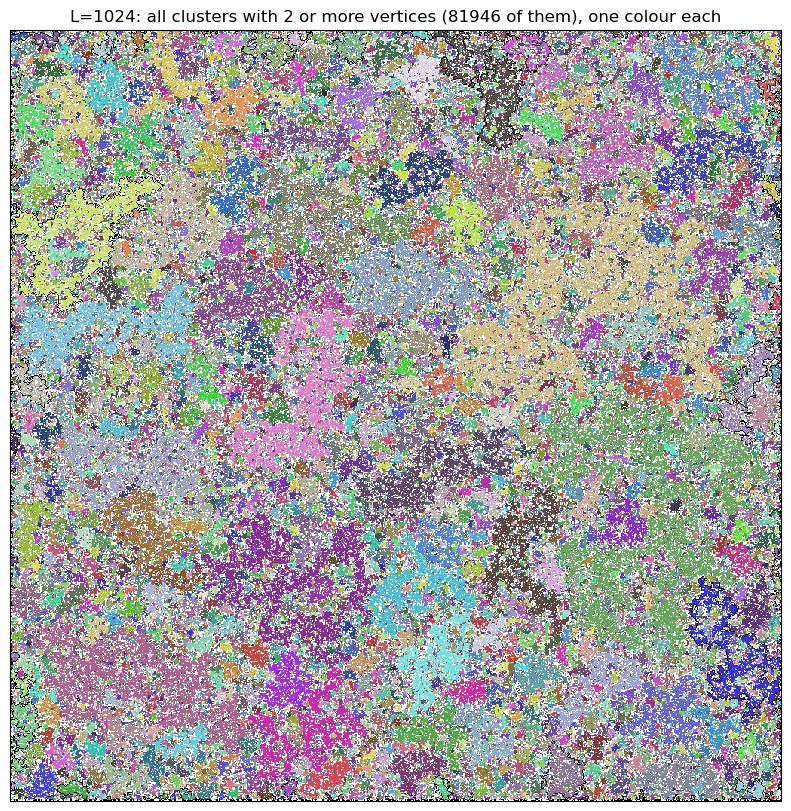

In [9]:
fig, info = dc.draw_clusters(L, omega1, omega2, mode="all")
plt.show()

## 5. Figures for the presentation

Same sample as above (section 3), drawn at slide size and saved in `Graficos/`.

guardado: C:\Users\bronk\Desktop\wwea 2.0\Ingenieria semestre 14\Simulacion Estocastico\Lab\Proyecto\6)simulation v4\Graficos\Funcion_Altura.png


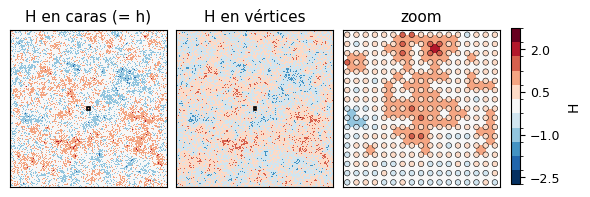

guardado: C:\Users\bronk\Desktop\wwea 2.0\Ingenieria semestre 14\Simulacion Estocastico\Lab\Proyecto\6)simulation v4\Graficos\Clusters_1024.png


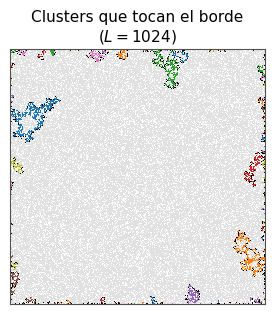

968 clústeres tocan el borde
guardado: C:\Users\bronk\Desktop\wwea 2.0\Ingenieria semestre 14\Simulacion Estocastico\Lab\Proyecto\6)simulation v4\Graficos\Dimension_clusters.png


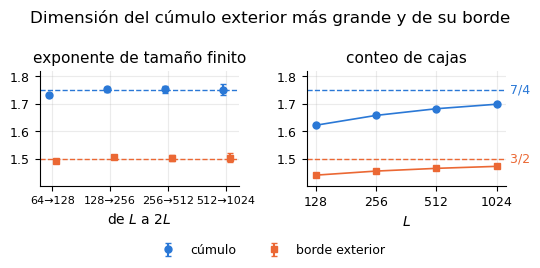

guardado: C:\Users\bronk\Desktop\wwea 2.0\Ingenieria semestre 14\Simulacion Estocastico\Lab\Proyecto\6)simulation v4\Graficos\Dimension_clusters_resumen.png


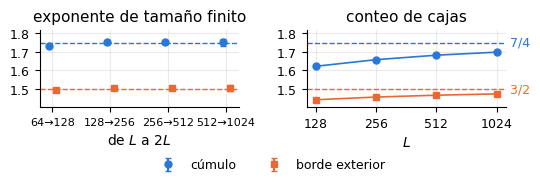

In [10]:
pf.figura_H(H, "Funcion_Altura.png")
pf.figura_clusters(L, omega1, omega2, "Clusters_1024.png", titulo=f"Clusters que tocan el borde\n($L = {L}$)")

# dimensions of the largest outermost cluster and of its outer boundary (res = dg.summarize(), section 1)
pf.figura_dimensiones(res, "Dimension_clusters.png")
pf.figura_dimensiones(res, "Dimension_clusters_resumen.png", titulo=None, alto=1.85)   # version for the written summary

## 6. Video
Three panels per frame: h | border clusters | face spins τ† = (−1)^h. Needs ffmpeg; if the cell complains, run `pip install imageio-ffmpeg` in the Anaconda Prompt once.

Cost per frame on your machine: about 0.07 s and 0.12 MB at L = 256, 0.27 s and 0.26 MB at L = 512. Consecutive frames are almost independent samples, so the picture flickers.

In [11]:
# at the critical point
dc.make_video("drc_critical.mp4", L=256, n_frames=300, fps=10, scale=2, seed=0)

'drc_critical.mp4'

In [12]:
# temperature sweep through the critical point: beta / beta_c goes from 0.85 to 1.15
n = 300
dc.make_video("drc_sweep_1.mp4", L=256, n_frames=n, fps=10, scale=2, seed=0, beta_ratio=np.linspace(0.85, 1.15, n))

'drc_sweep_1.mp4'

In [13]:
n = 300
u = np.linspace(-1, 1, n)
beta_ratio = 1 + 0.1 * np.sign(u) * np.abs(u) ** 2      # from 0.9 to 1.1, dense near 1
dc.make_video("drc_sweep_2.mp4", L=256, n_frames=n, fps=10, scale=2, seed=0, beta_ratio=beta_ratio)

'drc_sweep_2.mp4'